In [21]:
from pykidev import Pykiba, PykiDev, search_by_manufacturer,  serial_ports_list
import time
from pprint import pprint


name = "STMicroelectronics"       # Linux driver name for the Arduino Mega2560

ports_found = serial_ports_list()      # Return a list of all available serial ports

arduino_port = search_by_manufacturer(ports_found, name)                                      

print(f'\n\n  Computer comport of the arduino is: {arduino_port}')  

# Initialize communication with PykiDev..

ard = PykiDev(port = arduino_port, baudrate =115200) # by default baudrate = 9600 , colud be 115200 

#time.sleep(2) #must be a delay 

print(f'\n\n Returns the name of the project: {ard.command("hello")}') # This provides access to all Arduino commands
print(f'\n   The name of the project: {ard.hello() = }') # The commands are mapped to Python functions 

# In mode 1, the LED blinks twice
print(f'\n   Sets mode of operation of the Arduino. Returns setted mode:  { ard.command("mode",1) =}') 

# The 'mode' command can be called like a standard Python function: mode()
print(f'\n   Sets mode of operation of the Arduino. Returns setted mode:  { ard.mode(2) = } ' ) 

print('\n\n Global variables:')
print('[name, value, min, max, update flag]')
pprint(ard.varlst())#

#del ard  # To close comport and free it for next example



0.   None   /dev/ttyS0
1.   STMicroelectronics   /dev/ttyACM0


  Computer comport of the arduino is: /dev/ttyACM0


 Returns the name of the project: Protecta

   The name of the project: ard.hello() = 'Protecta'

   Sets mode of operation of the Arduino. Returns setted mode:   ard.command("mode",1) =1

   Sets mode of operation of the Arduino. Returns setted mode:   ard.mode(2) = 2 


 Global variables:
[name, value, min, max, update flag]
[['pid1m', 0.0, 0.0, 1.0, 0],
 ['pid0m', 0.0, 0.0, 1.0, 0],
 ['tau', 7.5, 0.05, 600.0, 0],
 ['kp', 1.96, 0.01, 1000.0, 0],
 ['sp1', 100.0, 0.0, 370.0, 0],
 ['sp0', 100.0, 0.0, 370.0, 0],
 ['pwm1', 0.0, 0.0, 100.0, 0],
 ['pwm0', 0.0, 0.0, 100.0, 0],
 ['t1', 29.33, 0.0, 0.0, 1],
 ['crdy', 1.0, 0.0, 0.0, 1]]


In [8]:
ard.hlp()

['varlst',
 'pid',
 'pid1m',
 'pid0m',
 'tau',
 'kp',
 'sp1',
 'sp0',
 'pwm1',
 'pwm0',
 't1',
 'crdy',
 'adcclr',
 'adctst',
 'sum3',
 'sum2',
 'sum1',
 'sum0',
 'buf3',
 'buf2',
 'buf1',
 'buf0',
 'mode',
 'hello',
 'echo',
 'hlp']

In [24]:
ard.adcclr()


1

In [27]:
ard.crdy()


1.0

In [28]:
a0 = ard.buf0()
a1 = ard.buf1()

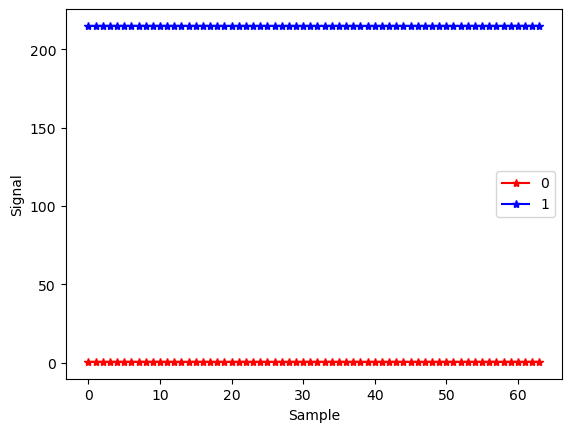

In [29]:
%matplotlib qt
import matplotlib.pyplot as plt
%matplotlib inline
plt.plot(a1,'r*-',  label=f'0')
plt.plot(a0,'b*-',  label=f'1')

plt.title("")
plt.xlabel("Sample")
plt.ylabel("Signal")
plt.legend()


plt.show()


In [30]:
print(len(a0))

64


In [31]:
%matplotlib qt

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation


#%matplotlib inline
# --- init animation ---
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()  # втора ордината (споделен X)

xdata = []
y1data, y2data = [], []

line1, = ax1.plot([], [], 'r-', label='f1')  # червен сигнал
#line2, = ax2.plot([], [], 'b-', label='f2')  # син сигнал

ax1.set_xlabel("Time / Frames")
ax1.set_ylabel(" ", color='r')
#ax2.set_ylabel("sin(t) f2", color='b')

max_points = 300

ard.pid1m(0)
ard.sp1(113)
ard.pid1m(1)


# ---  ---
def animate(i):
    v1 = ard.command('t1')
    #v2 = ard.command('t0')
    xdata.append(i)
    y1data.append(v1)
    #y2data.append(v2)
    plt.show()
    # ограничаваме броя на точките
    if len(xdata) > max_points:
        xdata.pop(0)
        y1data.pop(0)
        #y2data.pop(0)

    # обновяване на данните
    line1.set_data(range(len(y1data)), y1data)
    #line2.set_data(range(len(y2data)), y2data)

    # --- динамично мащабиране ---
    ax1.relim()          # преизчислява границите на оста
    ax1.autoscale_view() # мащабира според новите данни
    ax2.relim()
    ax2.autoscale_view()

    ax1.set_xlim(0, max_points)
    return line1 #, line2

anim = FuncAnimation(fig, animate, interval=1000, blit=False, cache_frame_data=False)
plt.show()

In [32]:

ard.pid1m(0)
#ard.sp1(113)
#ard.pid1m(1)

0.0

In [18]:
ard.sp1()

113.0

In [ ]:
1.23
1.24
1.31
1.29


In [81]:
ard.autoprn(1)
ard.adcclr()


In [20]:
del ard

In [10]:
import serial.tools.miniterm